# Skin Cancer Detection: Segmentation + Image-Clinical Fusion + Explainability
**Pipeline (follows the proposed methodology slide, in order):**
1. Data collection (HAM10000 images + clinical metadata, ISBI2016 masks)
2. Pre-processing: resizing, hair removal, normalization, data augmentation
3. Skin lesion segmentation: U-Net
4. ROI extraction
5. Feature extraction: image features (CNN) and clinical features
6. Feature fusion: autoencoder bottleneck
7. Classification: deep CNN (EfficientNetB0)
8. Explainability: Grad-CAM

**Notes**
- Split is grouped by `lesion_id` (no lesion appears in two splits). A random image-level split leaks near-duplicate images and gives fake 95-99% accuracy.
- `dx_type` (how the diagnosis was confirmed) is NOT used as an input: it correlates with the label and is not available for a new patient.
- Report the numbers this notebook actually produces. Academic prototype only, not a clinical diagnostic tool.

## 0. Setup

In [ ]:
!pip -q install opencv-python-headless scikit-learn pandas matplotlib seaborn pillow tqdm

In [ ]:
import os, glob, random, warnings, json, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             balanced_accuracy_score, f1_score, roc_auc_score)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

WORK_SIZE = 256   # working resolution (hair removal + ROI cropping)
SEG_SIZE  = 128   # U-Net input size
CLS_SIZE  = 224   # classifier input size (ROI)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data collection

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import glob

HAM_ROOT = "/content/drive/MyDrive/SkinSegmentation"

ISBI_IMAGE_DIR = os.path.join(
    HAM_ROOT,
    "images",
    "ISBI2016_ISIC_Part1_Training_Data"
)

ISBI_MASK_DIR = os.path.join(
    HAM_ROOT,
    "masks",
    "ISBI2016_ISIC_Part1_Training_GroundTruth"
)

print("HAM_ROOT:", HAM_ROOT)
print("ISBI_IMAGE_DIR:", ISBI_IMAGE_DIR)
print("ISBI_MASK_DIR:", ISBI_MASK_DIR)

# Verify directories
if not os.path.isdir(ISBI_IMAGE_DIR):
    raise FileNotFoundError(f"Images folder missing: {ISBI_IMAGE_DIR}")

if not os.path.isdir(ISBI_MASK_DIR):
    raise FileNotFoundError(f"Masks folder missing: {ISBI_MASK_DIR}")

# Collect files
image_files = glob.glob(ISBI_IMAGE_DIR + "/*")
mask_files = glob.glob(ISBI_MASK_DIR + "/*")

print("\nTotal Images:", len(image_files))
print("Total Masks:", len(mask_files))

print("\nSUCCESS: ISBI dataset paths detected!")

HAM_ROOT: /content/drive/MyDrive/SkinSegmentation
ISBI_IMAGE_DIR: /content/drive/MyDrive/SkinSegmentation/images/ISBI2016_ISIC_Part1_Training_Data
ISBI_MASK_DIR: /content/drive/MyDrive/SkinSegmentation/masks/ISBI2016_ISIC_Part1_Training_GroundTruth

Total Images: 900
Total Masks: 900

SUCCESS: ISBI dataset paths detected!


In [ ]:
import os
import glob
import pandas as pd
from pathlib import Path

# Dataset paths
HAM_ROOT = "/content/drive/MyDrive/SkinSegmentation"

ISBI_IMAGE_DIR = os.path.join(
    HAM_ROOT, "images",
    "ISBI2016_ISIC_Part1_Training_Data"
)

ISBI_MASK_DIR = os.path.join(
    HAM_ROOT, "masks",
    "ISBI2016_ISIC_Part1_Training_GroundTruth"
)

# Collect image files
image_files = (
    glob.glob(os.path.join(ISBI_IMAGE_DIR, "*.jpg")) +
    glob.glob(os.path.join(ISBI_IMAGE_DIR, "*.jpeg")) +
    glob.glob(os.path.join(ISBI_IMAGE_DIR, "*.png"))
)

# Collect mask files
mask_files = (
    glob.glob(os.path.join(ISBI_MASK_DIR, "*.png")) +
    glob.glob(os.path.join(ISBI_MASK_DIR, "*.jpg"))
)

# Create image map
image_map = {
    Path(p).stem: p for p in image_files
}

# Create mask map
mask_map = {
    Path(p).stem.replace("_Segmentation", ""): p
    for p in mask_files
}

# Find matching IDs
common_ids = sorted(
    set(image_map.keys()) & set(mask_map.keys())
)

# Create metadata
metadata = pd.DataFrame({
    "image_id": common_ids,
    "image_path": [image_map[i] for i in common_ids],
    "mask_path": [mask_map[i] for i in common_ids]
})

print("Total Images:", len(image_files))
print("Total Masks:", len(mask_files))
print("Matched pairs:", len(common_ids))

print("\nDataset Metadata:")
print(metadata.head())

assert len(metadata) > 0, "No matching pairs found!"

print("\nSUCCESS! ISBI dataset metadata created.")

Total Images: 900
Total Masks: 900
Matched pairs: 900

Dataset Metadata:
       image_id                                         image_path  \
0  ISIC_0000000  /content/drive/MyDrive/SkinSegmentation/images...   
1  ISIC_0000001  /content/drive/MyDrive/SkinSegmentation/images...   
2  ISIC_0000002  /content/drive/MyDrive/SkinSegmentation/images...   
3  ISIC_0000004  /content/drive/MyDrive/SkinSegmentation/images...   
4  ISIC_0000006  /content/drive/MyDrive/SkinSegmentation/images...   

                                           mask_path  
0  /content/drive/MyDrive/SkinSegmentation/masks/...  
1  /content/drive/MyDrive/SkinSegmentation/masks/...  
2  /content/drive/MyDrive/SkinSegmentation/masks/...  
3  /content/drive/MyDrive/SkinSegmentation/masks/...  
4  /content/drive/MyDrive/SkinSegmentation/masks/...  

SUCCESS! ISBI dataset metadata created.


In [ ]:
import os
import pandas as pd

HAM_ROOT = "/content/drive/MyDrive/HAM10000_Dataset"

metadata_path = os.path.join(
    HAM_ROOT,
    "HAM10000_metadata.csv"
)

metadata = pd.read_csv(metadata_path)

# Clean column names
metadata.columns = (
    metadata.columns.astype(str)
    .str.replace('\ufeff', '', regex=False)
    .str.strip()
)

print("Metadata loaded successfully!")
print("Columns:", metadata.columns.tolist())
print("\nDataset shape:", metadata.shape)
display(metadata.head())

if "dx" not in metadata.columns:
    raise KeyError("dx column missing! Check the CSV columns above.")

print("\nClass distribution:")
print(metadata["dx"].value_counts())

Metadata loaded successfully!
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Dataset shape: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

# Clean clinical columns and build labels
for c in ["age", "sex", "localization", "lesion_id"]:
    if c not in metadata.columns:
        metadata[c] = np.nan

metadata["age"] = pd.to_numeric(metadata["age"], errors="coerce")

metadata["sex"] = (
    metadata["sex"].fillna("unknown").astype(str).str.lower()
)

metadata["localization"] = (
    metadata["localization"].fillna("unknown").astype(str).str.lower()
)

metadata["lesion_id"] = (
    metadata["lesion_id"].fillna(metadata["image_id"]).astype(str)
)

# Remove rows without diagnosis labels
metadata = metadata.dropna(subset=["dx"]).copy()

# Build class labels
CLASS_NAMES = sorted(metadata["dx"].astype(str).unique().tolist())

class_to_id = {n: i for i, n in enumerate(CLASS_NAMES)}

metadata["label"] = metadata["dx"].astype(str).map(class_to_id).astype(int)

NUM_CLASSES = len(CLASS_NAMES)

print("Class mapping:", class_to_id)
print("Number of classes:", NUM_CLASSES)
print("Dataset shape:", metadata.shape)
print("\nClass distribution:")
print(metadata["dx"].value_counts())

Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Number of classes: 7
Dataset shape: (10015, 8)

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

# Check required columns
if "dx" not in metadata.columns:
    raise ValueError("Error: 'dx' column not found in metadata!")

if "image_id" not in metadata.columns:
    raise ValueError("Error: 'image_id' column not found!")

# Clean clinical columns
for c in ["age", "sex", "localization", "lesion_id"]:
    if c not in metadata.columns:
        metadata[c] = np.nan

# Convert age into numeric
metadata["age"] = pd.to_numeric(
    metadata["age"], errors="coerce"
)

# Handle missing clinical values
metadata["sex"] = (
    metadata["sex"].fillna("unknown").astype(str).str.lower()
)

metadata["localization"] = (
    metadata["localization"].fillna("unknown").astype(str).str.lower()
)

metadata["lesion_id"] = (
    metadata["lesion_id"].fillna(metadata["image_id"]).astype(str)
)

# Remove missing diagnosis labels
metadata = metadata.dropna(subset=["dx"]).copy()

# Generate class names
CLASS_NAMES = sorted(metadata["dx"].astype(str).unique().tolist())

# Create class mapping
class_to_id = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

# Generate numerical labels
metadata["label"] = (
    metadata["dx"].astype(str).map(class_to_id).astype(int)
)

NUM_CLASSES = len(CLASS_NAMES)

# Display results
print("Class mapping:", class_to_id)
print("Number of classes:", NUM_CLASSES)
print("Dataset shape:", metadata.shape)
print("\nClass distribution:")
print(metadata["dx"].value_counts())

Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Number of classes: 7
Dataset shape: (10015, 8)

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
import os

folders = [
    "/content/drive/MyDrive/SkinSegmentation",
    "/content/drive/MyDrive/HAM10000_Dataset"
]

for folder in folders:
    print("\n📁 FOLDER:", folder)

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.lower().endswith(".csv"):
                    print("CSV:", os.path.join(root, file))
    else:
        print("Folder not found!")


📁 FOLDER: /content/drive/MyDrive/SkinSegmentation

📁 FOLDER: /content/drive/MyDrive/HAM10000_Dataset
CSV: /content/drive/MyDrive/HAM10000_Dataset/HAM10000_metadata.csv


In [ ]:
# Clean clinical columns (age, sex, localization) and build labels
for c in ["age", "sex", "localization", "lesion_id"]:
    if c not in metadata.columns:
        metadata[c] = np.nan
metadata["age"] = pd.to_numeric(metadata["age"], errors="coerce")
metadata["sex"] = metadata["sex"].fillna("unknown").astype(str).str.lower()
metadata["localization"] = metadata["localization"].fillna("unknown").astype(str).str.lower()
metadata["lesion_id"] = metadata["lesion_id"].fillna(metadata["image_id"]).astype(str)

CLASS_NAMES = sorted(metadata["dx"].astype(str).unique().tolist())
class_to_id = {n: i for i, n in enumerate(CLASS_NAMES)}
metadata["label"] = metadata["dx"].astype(str).map(class_to_id).astype(int)
NUM_CLASSES = len(CLASS_NAMES)
print(class_to_id)

{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [ ]:
# Group-aware split (70/15/15) by lesion_id: no lesion appears in two splits
groups = metadata[["lesion_id", "label"]].drop_duplicates("lesion_id")
train_g, temp_g = train_test_split(groups, test_size=0.30, random_state=SEED, stratify=groups["label"])
val_g, test_g = train_test_split(temp_g, test_size=0.50, random_state=SEED, stratify=temp_g["label"])

train_df = metadata[metadata["lesion_id"].isin(train_g["lesion_id"])].reset_index(drop=True)
val_df   = metadata[metadata["lesion_id"].isin(val_g["lesion_id"])].reset_index(drop=True)
test_df  = metadata[metadata["lesion_id"].isin(test_g["lesion_id"])].reset_index(drop=True)
print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))
print("Lesion overlap train/val:", len(set(train_df.lesion_id) & set(val_df.lesion_id)))
print("Lesion overlap train/test:", len(set(train_df.lesion_id) & set(test_df.lesion_id)))

Train: 7002 Val: 1532 Test: 1481
Lesion overlap train/val: 0
Lesion overlap train/test: 0


## 2. Pre-processing: resizing, hair removal, normalization, augmentation

In [ ]:
def remove_hair(img_rgb):
    """DullRazor-style hair removal: black-hat filter -> hair mask -> inpainting."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    blackhat = cv2.GaussianBlur(blackhat, (3, 3), 0)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    return cv2.inpaint(img_rgb, hair_mask, 1, cv2.INPAINT_TELEA)

def load_clean(path, size=WORK_SIZE):
    """Read -> resize -> hair removal. Returns uint8 RGB (size x size x 3)."""
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    return remove_hair(rgb)

def normalize01(x):
    """Normalization to [0,1] (used by the U-Net). EfficientNet normalizes internally."""
    return x.astype(np.float32) / 255.0

In [ ]:
print("Columns:", train_df.columns.tolist())
print("\nFirst 5 rows:")
display(train_df.head())

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'label']

First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization,label
0,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,2
1,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,2
2,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,2
3,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,2
4,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face,2


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'sample_data']


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/HAM10000_Dataset"

for root, dirs, files in os.walk(DATASET_PATH):
    print("Folder:", root)
    print("Images:", len([f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]))
    print("Subfolders:", dirs)

Folder: /content/drive/MyDrive/HAM10000_Dataset
Images: 0
Subfolders: ['HAM10000_images_part_1', 'HAM10000_images_part_2']
Folder: /content/drive/MyDrive/HAM10000_Dataset/HAM10000_images_part_1
Images: 5000
Subfolders: []
Folder: /content/drive/MyDrive/HAM10000_Dataset/HAM10000_images_part_2
Images: 5015
Subfolders: []


In [ ]:
import os
import glob
import cv2
import matplotlib.pyplot as plt

# Dataset folders
IMAGE_DIRS = [
    "/content/drive/MyDrive/HAM10000_Dataset/HAM10000_images_part_1",
    "/content/drive/MyDrive/HAM10000_Dataset/HAM10000_images_part_2"
]

# Collect all image files
image_files = []

for folder in IMAGE_DIRS:
    image_files.extend(
        glob.glob(os.path.join(folder, "*.jpg"))
    )

print("Total images found:", len(image_files))

# Create image ID mapping
image_map = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in image_files
}

# Map image IDs to paths
train_df["image_path"] = train_df["image_id"].map(image_map)

# Keep valid images
valid_df = train_df.dropna(subset=["image_path"]).copy()

print("Matched images:", len(valid_df))
print("Missing images:", train_df["image_path"].isna().sum())

Total images found: 10015
Matched images: 7002
Missing images: 0


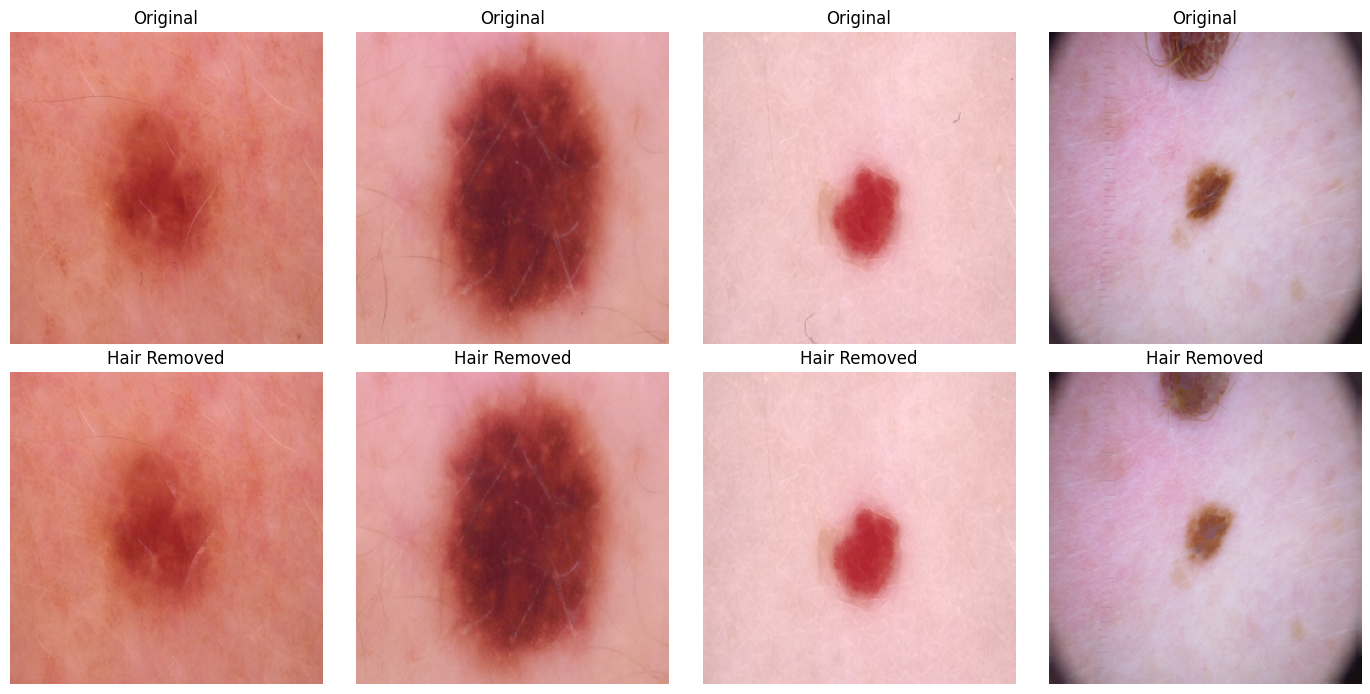

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7))

samples = valid_df.sample(
    n=min(4, len(valid_df)),
    random_state=1
)

for j, (_, row) in enumerate(samples.iterrows()):

    raw = cv2.imread(row["image_path"])

    raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)

    raw = cv2.resize(
        raw,
        (WORK_SIZE, WORK_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Original image
    ax[0, j].imshow(raw)
    ax[0, j].set_title("Original")
    ax[0, j].axis("off")

    # Hair removed image
    hair_removed = remove_hair(raw)

    ax[1, j].imshow(hair_removed)
    ax[1, j].set_title("Hair Removed")
    ax[1, j].axis("off")

# Hide unused columns if fewer than 4 samples
for j in range(len(samples), 4):
    ax[0, j].axis("off")
    ax[1, j].axis("off")

plt.tight_layout()
plt.show()

## 3. Skin lesion segmentation (U-Net trained on ISBI2016)

In [ ]:
def build_isbi_pairs(image_dir, mask_dir):
    imgs = glob.glob(os.path.join(image_dir, "*.jpg")) + glob.glob(os.path.join(image_dir, "*.png"))
    mask_map = {Path(m).stem.replace("_Segmentation", ""): m
                for m in glob.glob(os.path.join(mask_dir, "*.png"))}
    return sorted((im, mask_map[Path(im).stem]) for im in imgs if Path(im).stem in mask_map)

seg_pairs = build_isbi_pairs(ISBI_IMAGE_DIR, ISBI_MASK_DIR)
print("Matched ISBI image-mask pairs:", len(seg_pairs))
assert len(seg_pairs) > 0, "No ISBI pairs found"

def _load_pair(p):
    img = cv2.resize(load_clean(p[0]), (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(p[1], cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_NEAREST)
    return normalize01(img), (m > 127).astype(np.float32)[..., None]

with ThreadPoolExecutor(8) as ex:
    res = list(tqdm(ex.map(_load_pair, seg_pairs), total=len(seg_pairs), desc="Loading ISBI"))
X_seg = np.stack([r[0] for r in res]); Y_seg = np.stack([r[1] for r in res])
del res; gc.collect()
print("X_seg:", X_seg.shape, "Y_seg:", Y_seg.shape, "mask values:", np.unique(Y_seg))

Matched ISBI image-mask pairs: 900


Loading ISBI:   0%|          | 0/900 [00:00<?, ?it/s]

X_seg: (900, 128, 128, 3) Y_seg: (900, 128, 128, 1) mask values: [0. 1.]


In [ ]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    return x

def build_unet(input_shape=(SEG_SIZE, SEG_SIZE, 3)):
    inp = layers.Input(input_shape)
    c1 = conv_block(inp, 32); p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 64);  p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 128); p3 = layers.MaxPooling2D()(c3)
    c4 = conv_block(p3, 256); p4 = layers.MaxPooling2D()(c4)
    bn = conv_block(p4, 512)
    u4 = layers.Concatenate()([layers.UpSampling2D()(bn), c4]); c5 = conv_block(u4, 256)
    u3 = layers.Concatenate()([layers.UpSampling2D()(c5), c3]); c6 = conv_block(u3, 128)
    u2 = layers.Concatenate()([layers.UpSampling2D()(c6), c2]); c7 = conv_block(u2, 64)
    u1 = layers.Concatenate()([layers.UpSampling2D()(c7), c1]); c8 = conv_block(u1, 32)
    out = layers.Conv2D(1, 1, activation="sigmoid")(c8)
    return Model(inp, out, name="Skin_Lesion_UNet")

def dice_coef(y_true, y_pred, smooth=1e-6):
    yt = tf.reshape(tf.cast(y_true, tf.float32), [-1]); yp = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    return (2 * tf.reduce_sum(yt * yp) + smooth) / (tf.reduce_sum(yt) + tf.reduce_sum(yp) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    yt = tf.reshape(tf.cast(y_true > 0.5, tf.float32), [-1]); yp = tf.reshape(tf.cast(y_pred > 0.5, tf.float32), [-1])
    inter = tf.reduce_sum(yt * yp)
    return (inter + smooth) / (tf.reduce_sum(yt) + tf.reduce_sum(yp) - inter + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1 - dice_coef(y_true, y_pred))

# Data augmentation for segmentation (image and mask transformed together)
def seg_augment(img, mask):
    both = tf.concat([img, mask], axis=-1)
    both = tf.image.random_flip_left_right(both)
    both = tf.image.random_flip_up_down(both)
    both = tf.image.rot90(both, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img, mask = both[..., :3], both[..., 3:]
    img = tf.clip_by_value(tf.image.random_brightness(img, 0.1), 0.0, 1.0)
    return img, mask

Xtr_s, Xv_s, Ytr_s, Yv_s = train_test_split(X_seg, Y_seg, test_size=0.20, random_state=SEED)
train_seg_ds = (tf.data.Dataset.from_tensor_slices((Xtr_s, Ytr_s)).shuffle(512, seed=SEED)
                .map(seg_augment, num_parallel_calls=tf.data.AUTOTUNE).batch(16).prefetch(tf.data.AUTOTUNE))
val_seg_ds = tf.data.Dataset.from_tensor_slices((Xv_s, Yv_s)).batch(16)

unet = build_unet()
unet.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=bce_dice_loss, metrics=[dice_coef, iou_score])
unet_callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best_unet.weights.h5", monitor="val_dice_coef", mode="max",
                                       save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_dice_coef", mode="max", patience=10,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1),
]
history_seg = unet.fit(train_seg_ds, validation_data=val_seg_ds, epochs=60, callbacks=unet_callbacks, verbose=1)
print(dict(zip(unet.metrics_names, unet.evaluate(val_seg_ds, verbose=0))))

Epoch 1/60
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - dice_coef: 0.6048 - iou_score: 0.5252 - loss: 0.8989
Epoch 1: val_dice_coef improved from None to 0.43798, saving model to best_unet.weights.h5

Epoch 1: finished saving model to best_unet.weights.h5
45/45 ━━━━━━━━━━━━━━━━━━━━ 77s 571ms/step - dice_coef: 0.6400 - iou_score: 0.5818 - loss: 0.7772 - val_dice_coef: 0.4380 - val_iou_score: 0.2824 - val_loss: 5.1913 - learning_rate: 0.0010
Epoch 2/60
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - dice_coef: 0.7084 - iou_score: 0.6537 - loss: 0.6085
Epoch 2: val_dice_coef improved from 0.43798 to 0.59090, saving model to best_unet.weights.h5

Epoch 2: finished saving model to best_unet.weights.h5
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - dice_coef: 0.7208 - iou_score: 0.6622 - loss: 0.5830 - val_dice_coef: 0.5909 - val_iou_score: 0.4543 - val_loss: 0.8659 - learning_rate: 0.0010
Epoch 3/60
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - dice_coef: 0.7687 - iou_score: 0.7063 - loss: 0.4818
Epoch 3: v

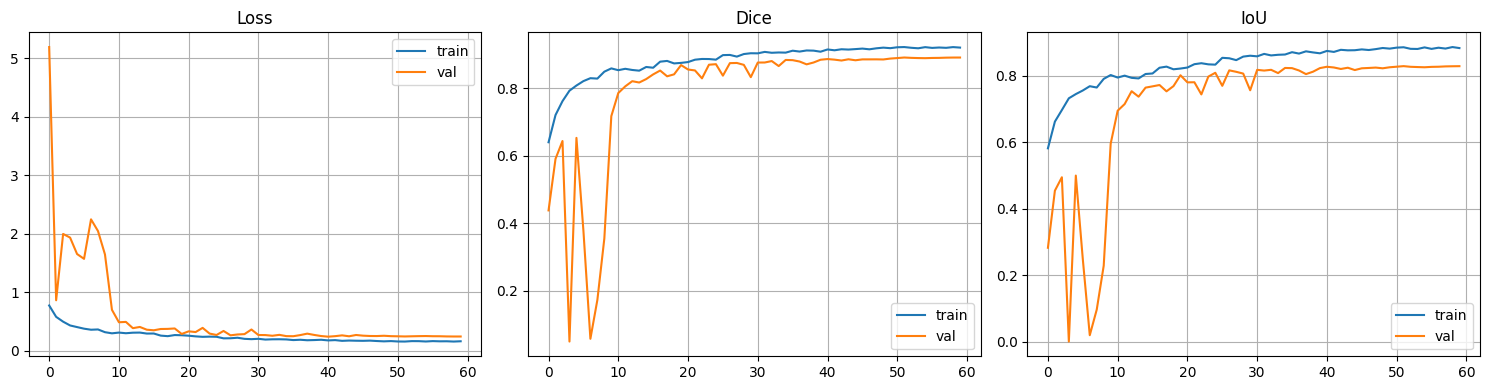

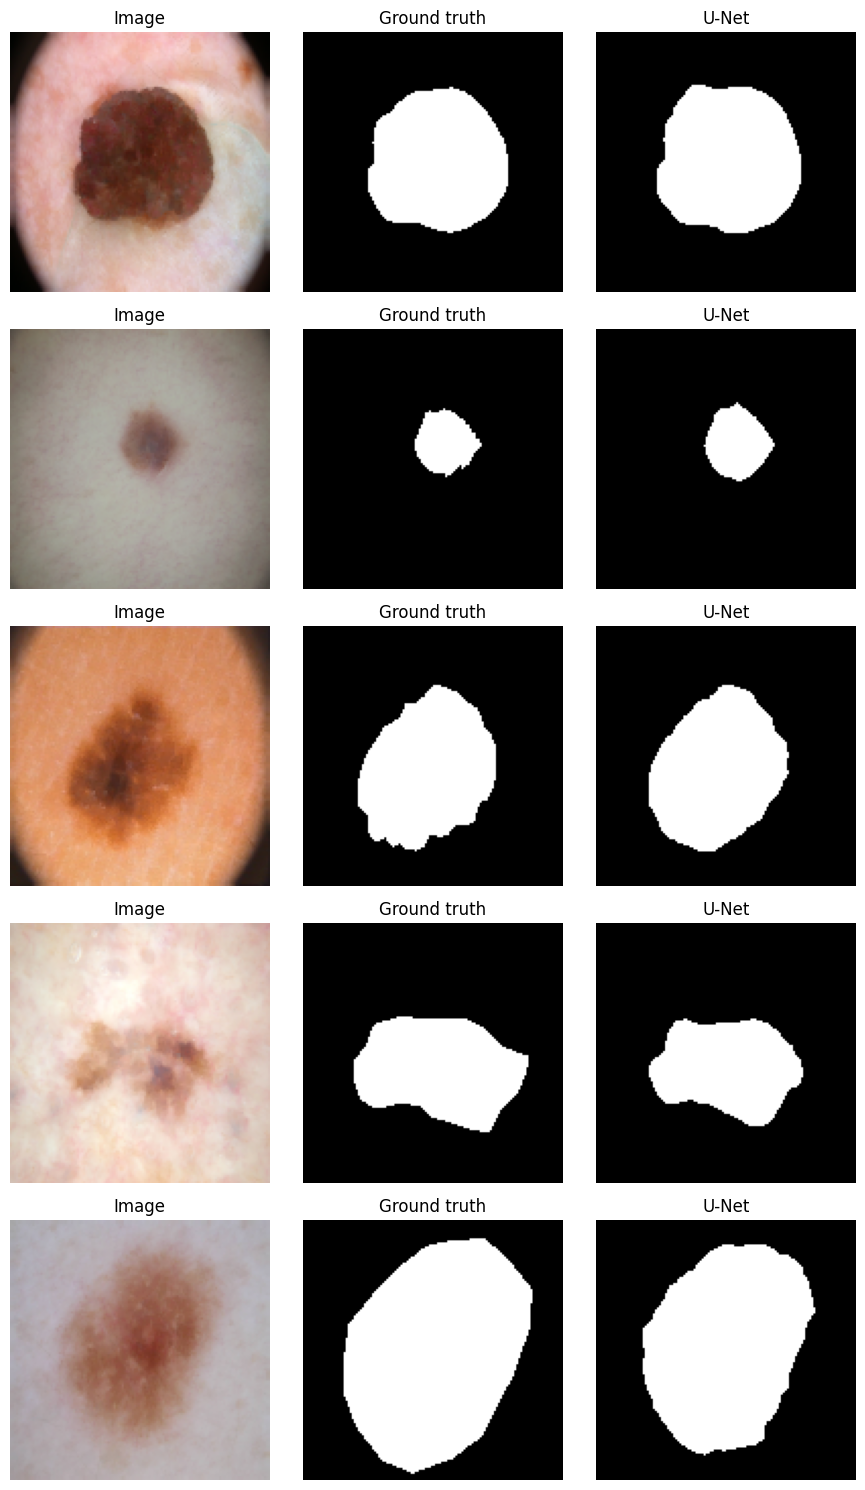

In [ ]:
# U-Net curves + visual check on held-out ISBI images
h = history_seg.history
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (k, t) in zip(ax, [("loss", "Loss"), ("dice_coef", "Dice"), ("iou_score", "IoU")]):
    a.plot(h[k], label="train"); a.plot(h["val_" + k], label="val"); a.set_title(t); a.legend(); a.grid()
plt.tight_layout(); plt.show()

pred = unet.predict(Xv_s[:5], verbose=0)
fig, ax = plt.subplots(5, 3, figsize=(9, 15))
for i in range(5):
    ax[i, 0].imshow(Xv_s[i]); ax[i, 0].set_title("Image")
    ax[i, 1].imshow(Yv_s[i, :, :, 0], cmap="gray"); ax[i, 1].set_title("Ground truth")
    ax[i, 2].imshow(pred[i, :, :, 0] > 0.5, cmap="gray"); ax[i, 2].set_title("U-Net")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()

## 4. ROI extraction
The U-Net mask is applied to every HAM10000 image (hair removal, then segmentation, then largest connected component, then bounding-box crop with a margin, then resize to 224). If the predicted mask is empty or implausible (<1% or >95% of the image), the full image is used as a fallback.

In [ ]:
# Add image_path to all dataset splits

train_df["image_path"] = train_df["image_id"].map(image_map)
val_df["image_path"]   = val_df["image_id"].map(image_map)
test_df["image_path"]  = test_df["image_id"].map(image_map)

# Check missing images
print("Train missing:", train_df["image_path"].isna().sum())
print("Validation missing:", val_df["image_path"].isna().sum())
print("Test missing:", test_df["image_path"].isna().sum())

# Remove rows with missing image paths, if any
train_df = train_df.dropna(subset=["image_path"]).copy()
val_df = val_df.dropna(subset=["image_path"]).copy()
test_df = test_df.dropna(subset=["image_path"]).copy()

print("\nDataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train missing: 0
Validation missing: 0
Test missing: 0

Dataset sizes:
Train: 7002
Validation: 1532
Test: 1481


In [ ]:
X_train_roi = build_roi_split(train_df, "Train")
X_val_roi   = build_roi_split(val_df, "Val")
X_test_roi  = build_roi_split(test_df, "Test")

print(X_train_roi.shape)
print(X_val_roi.shape)
print(X_test_roi.shape)

Train load+hair removal:   0%|          | 0/7002 [00:00<?, ?it/s]

Train: ROI found for 99.0% of images (rest use full image)


Val load+hair removal:   0%|          | 0/1532 [00:00<?, ?it/s]

Val: ROI found for 99.3% of images (rest use full image)


Test load+hair removal:   0%|          | 0/1481 [00:00<?, ?it/s]

Test: ROI found for 99.3% of images (rest use full image)
(7002, 224, 224, 3)
(1532, 224, 224, 3)
(1481, 224, 224, 3)


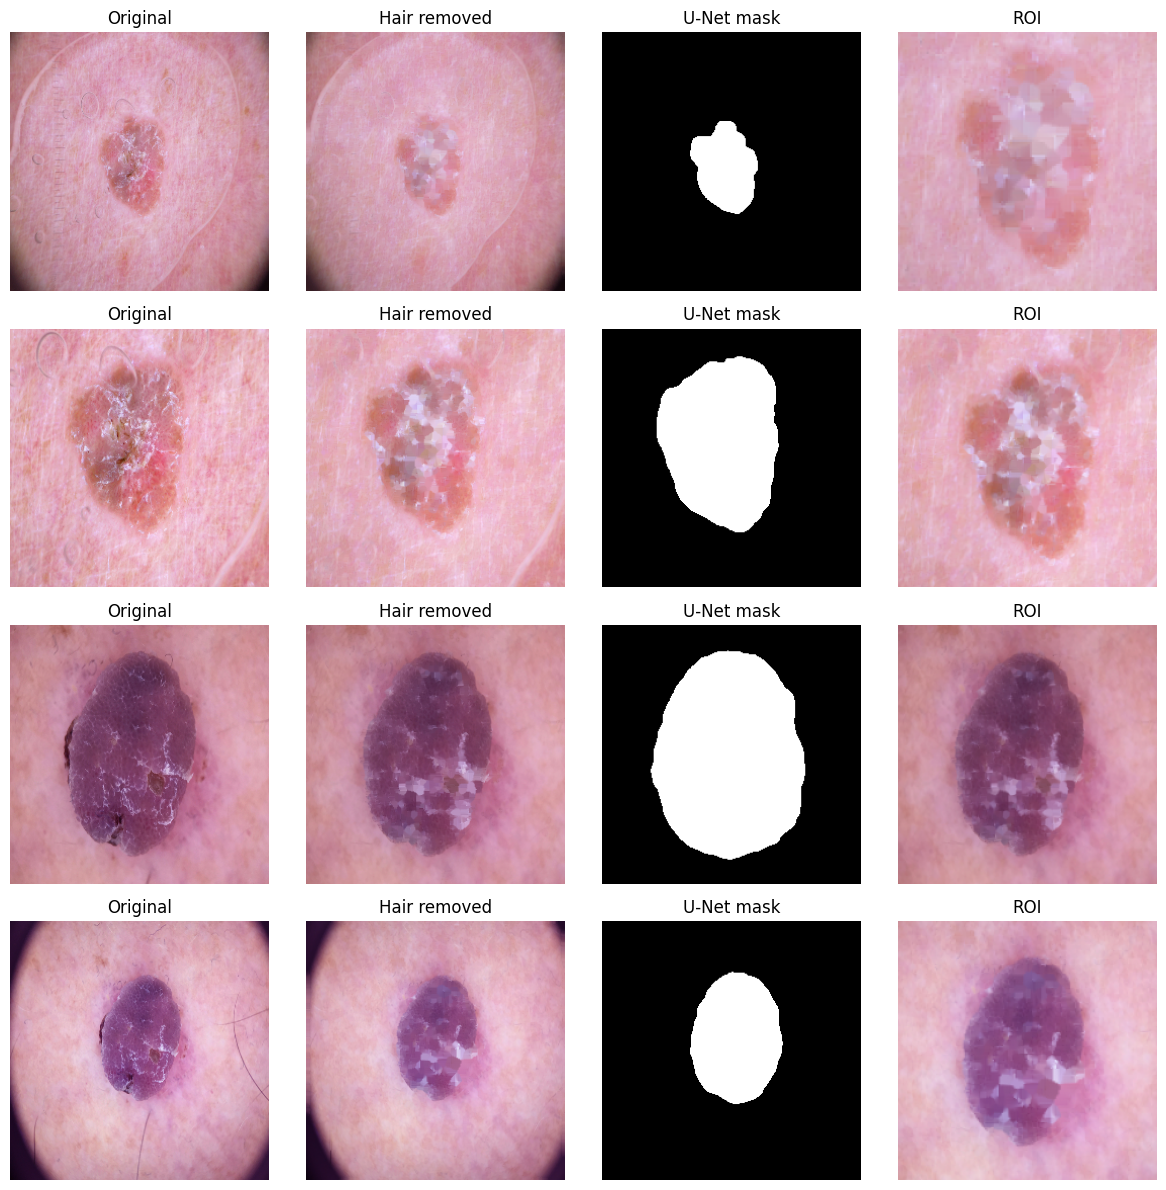

In [ ]:
# Visual check: original -> hair removed -> predicted mask -> ROI
fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for i, p in enumerate(test_df["image_path"].iloc[:4]):
    raw = cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (WORK_SIZE, WORK_SIZE))
    cleaned, m, roi, ok = preprocess_one(p)
    for a, im, t in zip(ax[i], [raw, cleaned, m, roi], ["Original", "Hair removed", "U-Net mask", "ROI"]):
        a.imshow(im, cmap="gray" if t == "U-Net mask" else None); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Feature extraction
- **Image features:** EfficientNetB0 backbone on the ROI (built inside the model in section 7).
- **Clinical features:** age (median-imputed, scaled) + sex and localization (one-hot). Preprocessor is fit on the training set only.

In [ ]:
CLINICAL_NUM = ["age"]
CLINICAL_CAT = ["sex", "localization"]

clinical_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), CLINICAL_NUM),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CLINICAL_CAT),
])

def dense32(x):
    if hasattr(x, "toarray"):
        x = x.toarray()
    return np.asarray(x, dtype=np.float32)

cols = CLINICAL_NUM + CLINICAL_CAT
X_train_clin = dense32(clinical_preprocessor.fit_transform(train_df[cols]))
X_val_clin   = dense32(clinical_preprocessor.transform(val_df[cols]))
X_test_clin  = dense32(clinical_preprocessor.transform(test_df[cols]))
y_train = train_df["label"].to_numpy(np.int32)
y_val   = val_df["label"].to_numpy(np.int32)
y_test  = test_df["label"].to_numpy(np.int32)
print("Clinical dim:", X_train_clin.shape[1], "| classes:", CLASS_NAMES)

Clinical dim: 19 | classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


### Data augmentation for the classifier
Flips, 90-degree rotations, brightness / contrast / saturation jitter (training only). Class-balancing weights are passed as sample weights.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH = 32

counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_w = (counts.sum() / (NUM_CLASSES * np.maximum(counts, 1))).astype(np.float32)
print("Class counts:", dict(zip(CLASS_NAMES, counts.tolist())))
print("Class weights:", dict(zip(CLASS_NAMES, class_w.round(2).tolist())))

def cls_augment(inputs, label, w):
    img, clin = inputs
    img = tf.cast(img, tf.float32)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, 20.0)
    img = tf.image.random_contrast(img, 0.85, 1.15)
    img = tf.image.random_saturation(img, 0.85, 1.15)
    img = tf.clip_by_value(img, 0.0, 255.0)
    return (img, clin), label, w

def make_ds(X, C, y, training):
    n = len(y)
    def gen():
        idx = np.random.permutation(n) if training else np.arange(n)
        for i in idx:
            yield (X[i], C[i]), y[i], class_w[y[i]]
    sig = ((tf.TensorSpec((CLS_SIZE, CLS_SIZE, 3), tf.uint8),
            tf.TensorSpec((C.shape[1],), tf.float32)),
           tf.TensorSpec((), tf.int32), tf.TensorSpec((), tf.float32))
    ds = tf.data.Dataset.from_generator(gen, output_signature=sig)
    if training:
        ds = ds.map(cls_augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda x, l, w: ((tf.cast(x[0], tf.float32), x[1]), l, w))
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(X_train_roi, X_train_clin, y_train, True)
val_ds   = make_ds(X_val_roi, X_val_clin, y_val, False)

Class counts: {'akiec': 230, 'bcc': 366, 'bkl': 774, 'df': 76, 'mel': 778, 'nv': 4679, 'vasc': 99}
Class weights: {'akiec': 4.349999904632568, 'bcc': 2.7300000190734863, 'bkl': 1.2899999618530273, 'df': 13.15999984741211, 'mel': 1.2899999618530273, 'nv': 0.20999999344348907, 'vasc': 10.100000381469727}


## 6-7. Feature fusion (autoencoder) + deep CNN classification
Image features (EfficientNetB0) and clinical features are concatenated and compressed by an **autoencoder bottleneck** (the encoder output is the fused representation; a decoder reconstructs the concatenated features as an auxiliary loss). The fused latent vector feeds the classification head. Trained end to end, so there is no train/test feature leakage from a separate stacking stage.

In [ ]:
IMG_FEAT, CLIN_FEAT, LATENT = 256, 32, 128

@tf.keras.utils.register_keras_serializable(package="skin")
class ReconstructionLoss(layers.Layer):
    """Adds an autoencoder reconstruction loss; passes the latent vector through unchanged."""
    def __init__(self, weight=0.1, **kwargs):
        super().__init__(**kwargs)
        self.weight = weight
    def call(self, inputs):
        target, recon, latent = inputs
        self.add_loss(self.weight * tf.reduce_mean(tf.square(tf.stop_gradient(target) - recon)))
        return latent
    def get_config(self):
        cfg = super().get_config(); cfg.update({"weight": self.weight}); return cfg

def build_fusion_model(clin_dim, num_classes):
    img_in = layers.Input((CLS_SIZE, CLS_SIZE, 3), name="roi_image")          # pixel range 0-255
    base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                                input_shape=(CLS_SIZE, CLS_SIZE, 3))
    base.trainable = False
    conv = base(img_in, training=False)                                        # EfficientNet normalizes internally
    x = layers.GlobalAveragePooling2D(name="img_gap")(conv)
    x = layers.Dropout(0.3)(x)
    img_feat = layers.Dense(IMG_FEAT, activation="relu", name="image_features")(x)

    clin_in = layers.Input((clin_dim,), name="clinical")
    c = layers.Dense(64, activation="relu")(clin_in)
    c = layers.BatchNormalization()(c)
    c = layers.Dropout(0.2)(c)
    clin_feat = layers.Dense(CLIN_FEAT, activation="relu", name="clinical_features")(c)

    concat = layers.Concatenate(name="feature_concat")([img_feat, clin_feat])
    e = layers.Dense(128, activation="relu")(concat)
    e = layers.BatchNormalization()(e)
    latent = layers.Dense(LATENT, activation="relu", name="fusion_latent")(e)   # fused features
    d = layers.Dense(128, activation="relu")(latent)
    recon = layers.Dense(IMG_FEAT + CLIN_FEAT, name="reconstruction")(d)
    latent = ReconstructionLoss(0.1, name="ae_loss")([concat, recon, latent])

    h = layers.Dropout(0.3)(latent)
    h = layers.Dense(128, activation="relu")(h)
    h = layers.Dropout(0.3)(h)
    out = layers.Softmax(name="class_output")(layers.Dense(num_classes)(h))
    model = Model([img_in, clin_in], out, name="EfficientNetB0_Autoencoder_Fusion")
    return model, base, conv

model, backbone, conv_tensor = build_fusion_model(X_train_clin.shape[1], NUM_CLASSES)
cam_model = Model(model.inputs, [conv_tensor, model.output])   # used later for Grad-CAM
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "EfficientNetB0_Autoencoder_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ roi_image           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical            │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ roi_image[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      1,280 │ clinical[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_gap             │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ img_gap[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 256)       │    327,936 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_features   │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_concat      │ (None, 288)       │          0 │ image_features[0… │
│ (Concatenate)       │                   │            │ clinical_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     36,992 │ feature_concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_latent       │ (None, 128)       │     16,512 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     16,512 │ fusion_latent[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (None, 288)       │     37,152 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ae_loss             │ (None, 128)       │          0 │ feature_concat[0… │
│ (ReconstructionLos… │                   │            │ reconstruction[0… │
│                     │                   │            │ fusion_latent[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ ae_loss[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,506,218 (17.19 MB)

 Trainable params: 456,263 (1.74 MB)

 Non-trainable params: 4,049,955 (15.45 MB)

In [ ]:
# Stage 1: Train new layers with frozen backbone

import os

SAVE_DIR = "/content/drive/MyDrive/SkinCancer_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

ckpt = tf.keras.callbacks.ModelCheckpoint(
    os.path.join(SAVE_DIR, "best_fusion.weights.h5"),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

cb = [
    ckpt,

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=cb,
    verbose=1
)

Epoch 1/20
    219/Unknown 55s 128ms/step - accuracy: 0.6493 - loss: 0.8935
Epoch 1: val_accuracy improved from None to 0.60052, saving model to /content/drive/MyDrive/SkinCancer_Models/best_fusion.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/SkinCancer_Models/best_fusion.weights.h5
219/219 ━━━━━━━━━━━━━━━━━━━━ 72s 207ms/step - accuracy: 0.6341 - loss: 0.8641 - val_accuracy: 0.6005 - val_loss: 1.3098 - learning_rate: 5.0000e-04
Epoch 2/20
218/219 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6523 - loss: 0.8454
Epoch 2: val_accuracy improved from 0.60052 to 0.62272, saving model to /content/drive/MyDrive/SkinCancer_Models/best_fusion.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/SkinCancer_Models/best_fusion.weights.h5
219/219 ━━━━━━━━━━━━━━━━━━━━ 30s 138ms/step - accuracy: 0.6470 - loss: 0.8233 - val_accuracy: 0.6227 - val_loss: 1.2373 - learning_rate: 5.0000e-04
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.6421 - 

In [ ]:
# Stage 2: fine-tune the last layers of EfficientNetB0 (BatchNorm layers stay frozen)
backbone.trainable = True
for l in backbone.layers[:-80]:
    l.trainable = False
for l in backbone.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cb2 = [tf.keras.callbacks.ModelCheckpoint("best_fusion.weights.h5", monitor="val_accuracy", mode="max",
                                          save_best_only=True, save_weights_only=True, verbose=1),
       tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=8,
                                        restore_best_weights=True, verbose=1),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1)]
history_2 = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=cb2, verbose=1)

Epoch 1/40
    219/Unknown 93s 192ms/step - accuracy: 0.6565 - loss: 0.9029
Epoch 1: val_accuracy improved from None to 0.64491, saving model to best_fusion.weights.h5

Epoch 1: finished saving model to best_fusion.weights.h5
219/219 ━━━━━━━━━━━━━━━━━━━━ 108s 262ms/step - accuracy: 0.6630 - loss: 0.8260 - val_accuracy: 0.6449 - val_loss: 1.4625 - learning_rate: 1.0000e-04
Epoch 2/40
218/219 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6870 - loss: 0.7403
Epoch 2: val_accuracy did not improve from 0.64491
219/219 ━━━━━━━━━━━━━━━━━━━━ 16s 74ms/step - accuracy: 0.6792 - loss: 0.7595 - val_accuracy: 0.4576 - val_loss: 1.2661 - learning_rate: 1.0000e-04
Epoch 3/40
218/219 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6813 - loss: 0.7365
Epoch 3: val_accuracy improved from 0.64491 to 0.64556, saving model to best_fusion.weights.h5

Epoch 3: finished saving model to best_fusion.weights.h5
219/219 ━━━━━━━━━━━━━━━━━━━━ 17s 78ms/step - accuracy: 0.6724 - loss: 0.7175 - val_accuracy: 0.6456 

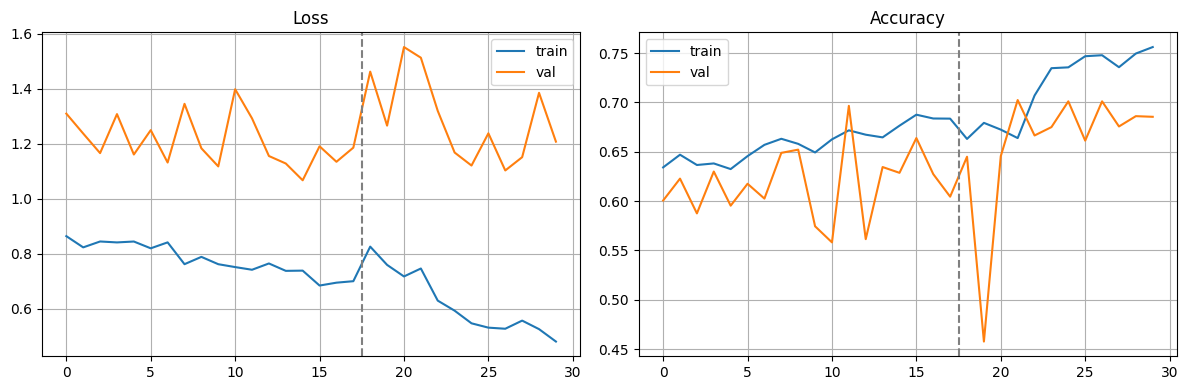

In [ ]:
# Training curves (both stages)
acc = history_1.history["accuracy"] + history_2.history["accuracy"]
vacc = history_1.history["val_accuracy"] + history_2.history["val_accuracy"]
loss = history_1.history["loss"] + history_2.history["loss"]
vloss = history_1.history["val_loss"] + history_2.history["val_loss"]
split = len(history_1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss, label="train"); ax[0].plot(vloss, label="val"); ax[0].axvline(split - 0.5, ls="--", c="gray"); ax[0].set_title("Loss"); ax[0].legend(); ax[0].grid()
ax[1].plot(acc, label="train"); ax[1].plot(vacc, label="val"); ax[1].axvline(split - 0.5, ls="--", c="gray"); ax[1].set_title("Accuracy"); ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

## 8. Evaluation on the held-out test set (with and without test-time augmentation)

In [ ]:
def predict_probs(X, C, tta=True, chunk=256):
    views = [(k, f) for f in (False, True) for k in range(4)] if tta else [(0, False)]
    out = np.zeros((len(X), NUM_CLASSES), np.float32)
    for k, f in views:
        for s in range(0, len(X), chunk):
            xb = np.rot90(X[s:s + chunk], k, axes=(1, 2))
            if f:
                xb = xb[:, :, ::-1]
            xb = np.ascontiguousarray(xb).astype(np.float32)
            out[s:s + chunk] += model.predict([xb, C[s:s + chunk]], batch_size=64, verbose=0)
    return out / len(views)

def report(probs, y, title):
    pred = probs.argmax(1)
    print(f"--- {title} ---")
    print(f"Accuracy          : {accuracy_score(y, pred):.4f}")
    print(f"Balanced accuracy : {balanced_accuracy_score(y, pred):.4f}")
    print(f"Macro F1          : {f1_score(y, pred, average='macro'):.4f}")
    try:
        print(f"Macro AUC (OvR)   : {roc_auc_score(y, probs, multi_class='ovr'):.4f}")
    except Exception as e:
        print("AUC skipped:", e)
    return pred

probs_plain = predict_probs(X_test_roi, X_test_clin, tta=False)
probs_tta = predict_probs(X_test_roi, X_test_clin, tta=True)
report(probs_plain, y_test, "Test (no TTA)")
y_pred = report(probs_tta, y_test, "Test (8-view TTA)")
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))

--- Test (no TTA) ---
Accuracy          : 0.7326
Balanced accuracy : 0.6628
Macro F1          : 0.5792
Macro AUC (OvR)   : 0.9311
--- Test (8-view TTA) ---
Accuracy          : 0.7265
Balanced accuracy : 0.6620
Macro F1          : 0.5788
Macro AUC (OvR)   : 0.9319

              precision    recall  f1-score   support

       akiec       0.34      0.61      0.44        46
         bcc       0.59      0.72      0.65        71
         bkl       0.57      0.63      0.60       168
          df       0.69      0.55      0.61        20
         mel       0.35      0.56      0.43       165
          nv       0.97      0.78      0.86       992
        vasc       0.33      0.79      0.47        19

    accuracy                           0.73      1481
   macro avg       0.55      0.66      0.58      1481
weighted avg       0.80      0.73      0.75      1481



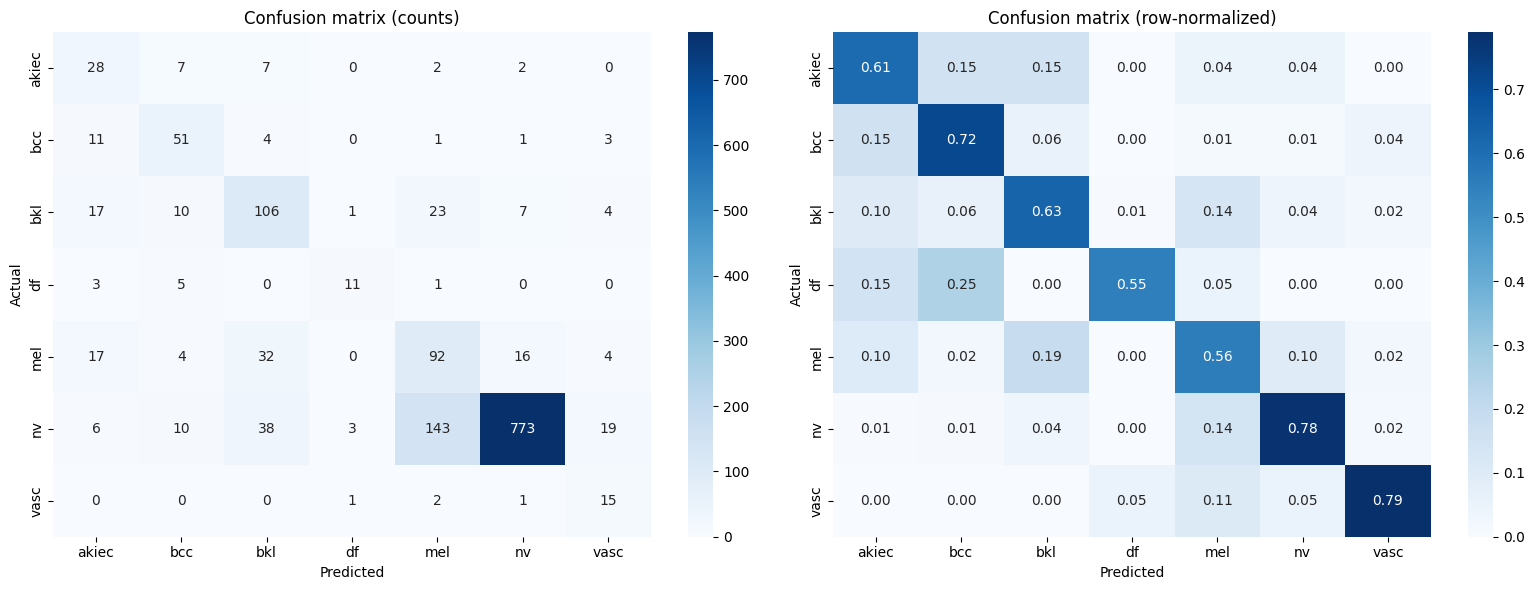

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
ax[1].set_title("Confusion matrix (row-normalized)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 9. Explainability: Grad-CAM

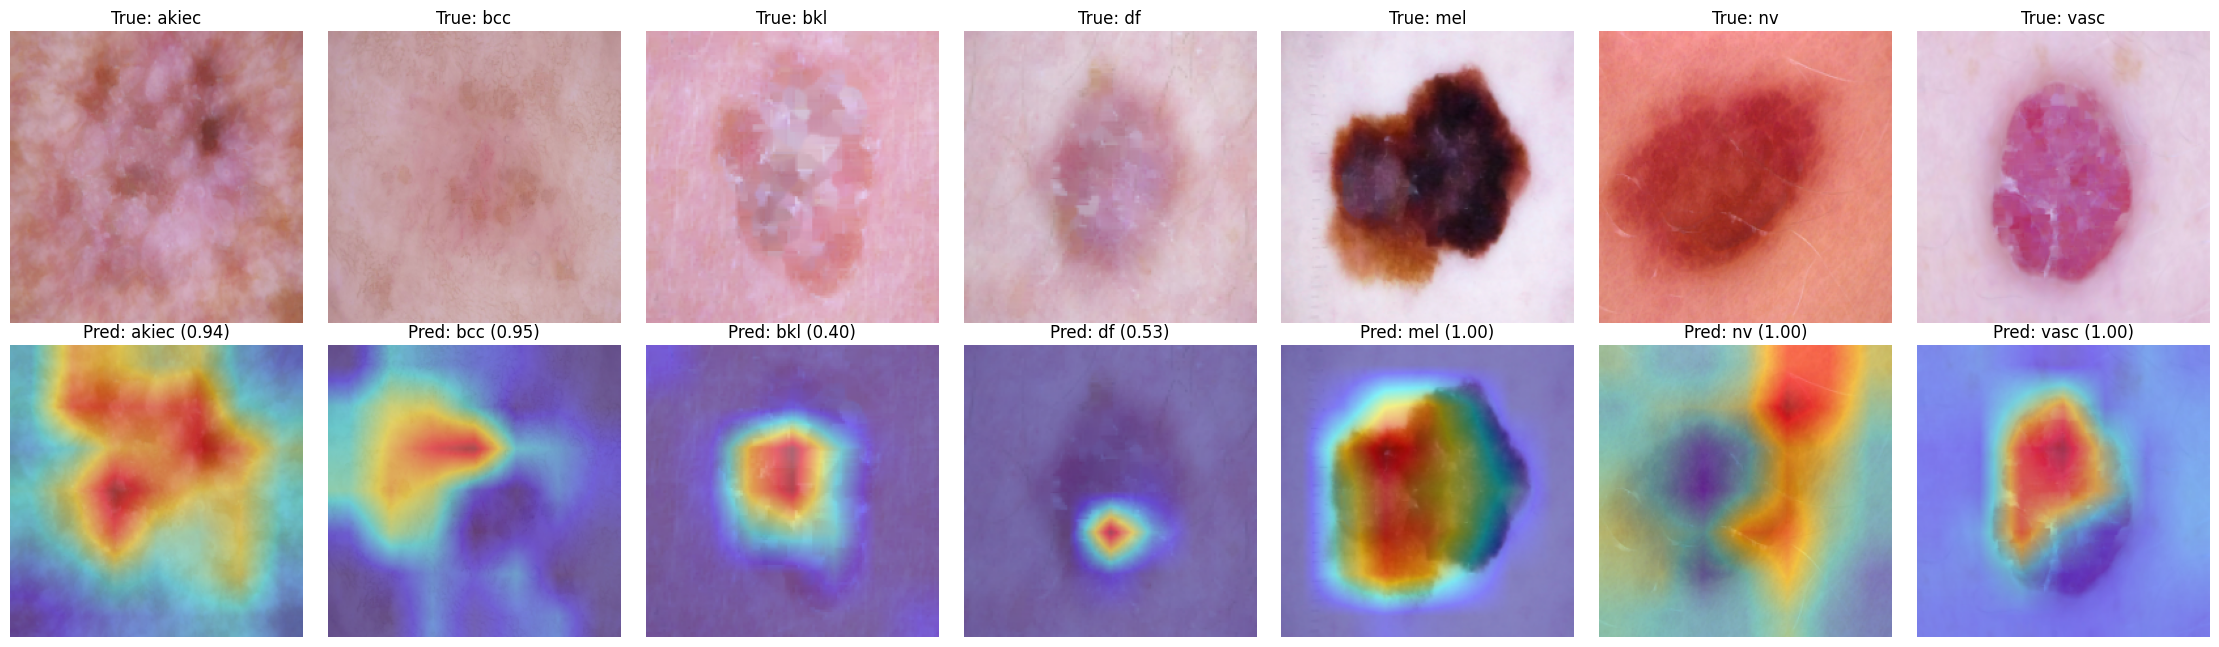

In [ ]:
def grad_cam(img_uint8, clin_vec, class_idx=None):
    img = tf.convert_to_tensor(img_uint8[None].astype(np.float32))
    clin = tf.convert_to_tensor(clin_vec[None].astype(np.float32))
    with tf.GradientTape() as tape:
        conv_out, preds = cam_model([img, clin], training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cv2.resize(cam, (CLS_SIZE, CLS_SIZE)), class_idx, preds[0].numpy()

def show_gradcam(indices):
    fig, ax = plt.subplots(2, len(indices), figsize=(3.2 * len(indices), 6.5))
    for j, i in enumerate(indices):
        cam, cidx, pr = grad_cam(X_test_roi[i], X_test_clin[i])
        heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1]
        overlay = (0.55 * X_test_roi[i] + 0.45 * heat).astype(np.uint8)
        ax[0, j].imshow(X_test_roi[i]); ax[0, j].axis("off")
        ax[0, j].set_title(f"True: {CLASS_NAMES[y_test[i]]}")
        ax[1, j].imshow(overlay); ax[1, j].axis("off")
        ax[1, j].set_title(f"Pred: {CLASS_NAMES[cidx]} ({pr[cidx]:.2f})")
    plt.tight_layout(); plt.show()

# one example per class (first test sample of each class)
sel = [int(np.where(y_test == c)[0][0]) for c in range(NUM_CLASSES) if (y_test == c).any()]
show_gradcam(sel)

## 10. Inference on a single image + clinical inputs

Predicted: bkl | true: bkl
{'akiec': np.float32(0.0856), 'bcc': np.float32(0.3608), 'bkl': np.float32(0.4046), 'df': np.float32(0.0008), 'mel': np.float32(0.09), 'nv': np.float32(0.0346), 'vasc': np.float32(0.0235)}


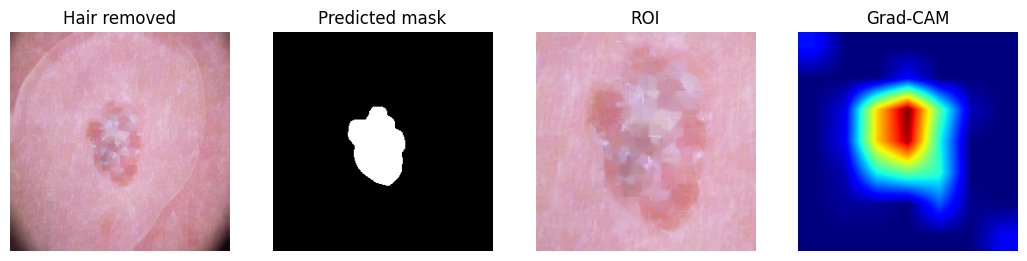

In [ ]:
def predict_single(image_path, age, sex, localization):
    cleaned, mask, roi, ok = preprocess_one(image_path)
    row = pd.DataFrame([{"age": age, "sex": str(sex).lower(), "localization": str(localization).lower()}])
    clin = dense32(clinical_preprocessor.transform(row[CLINICAL_NUM + CLINICAL_CAT]))
    prob = model.predict([roi[None].astype(np.float32), clin], verbose=0)[0]
    cam, cidx, _ = grad_cam(roi, clin[0])
    return prob, cleaned, mask, roi, cam

r0 = test_df.iloc[0]
prob, cleaned, mask, roi, cam = predict_single(r0["image_path"], r0["age"], r0["sex"], r0["localization"])
print("Predicted:", CLASS_NAMES[int(prob.argmax())], "| true:", r0["dx"])
print(dict(zip(CLASS_NAMES, prob.round(4))))
fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
for a, im, t in zip(ax, [cleaned, mask, roi, cam], ["Hair removed", "Predicted mask", "ROI", "Grad-CAM"]):
    a.imshow(im, cmap="gray" if t == "Predicted mask" else ("jet" if t == "Grad-CAM" else None)); a.set_title(t); a.axis("off")
plt.show()

## 11. Save models and metadata

In [ ]:
import joblib
OUTPUT_DIR = "/content/drive/MyDrive/SkinCancerProject_Models"
os.makedirs(OUTPUT_DIR, exist_ok=True)

unet.save_weights(os.path.join(OUTPUT_DIR, "unet.weights.h5"))
model.save_weights(os.path.join(OUTPUT_DIR, "fusion_model.weights.h5"))
try:
    model.save(os.path.join(OUTPUT_DIR, "fusion_model.keras"))
except Exception as e:
    print("Full-model save skipped (weights saved instead):", e)
joblib.dump(clinical_preprocessor, os.path.join(OUTPUT_DIR, "clinical_preprocessor.joblib"))
with open(os.path.join(OUTPUT_DIR, "meta.json"), "w") as f:
    json.dump({"class_names": CLASS_NAMES, "class_to_id": class_to_id,
               "clinical_numeric": CLINICAL_NUM, "clinical_categorical": CLINICAL_CAT,
               "work_size": WORK_SIZE, "seg_size": SEG_SIZE, "cls_size": CLS_SIZE}, f, indent=2)
print("Saved to:", OUTPUT_DIR, os.listdir(OUTPUT_DIR))

Saved to: /content/drive/MyDrive/SkinCancerProject_Models ['unet.weights.h5', 'fusion_model.weights.h5', 'fusion_model.keras', 'clinical_preprocessor.joblib', 'meta.json']


Stage 1 – Data Collection Output

In [ ]:
print("=" * 55)
print("STAGE 1: DATA COLLECTION")
print("=" * 55)

print("Total metadata records:", len(metadata))
print("Total classes:", NUM_CLASSES)
print("Class names:", CLASS_NAMES)

print("\nDataset Split:")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nClass Distribution:")
print(metadata["dx"].value_counts())

print("\nLesion overlap:")
print("Train-Val:",
      len(set(train_df.lesion_id) & set(val_df.lesion_id)))
print("Train-Test:",
      len(set(train_df.lesion_id) & set(test_df.lesion_id)))

STAGE 1: DATA COLLECTION
Total metadata records: 10015
Total classes: 7
Class names: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

Dataset Split:
Training images: 7002
Validation images: 1532
Testing images: 1481

Class Distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Lesion overlap:
Train-Val: 0
Train-Test: 0


stage 2 – Preprocessing Output

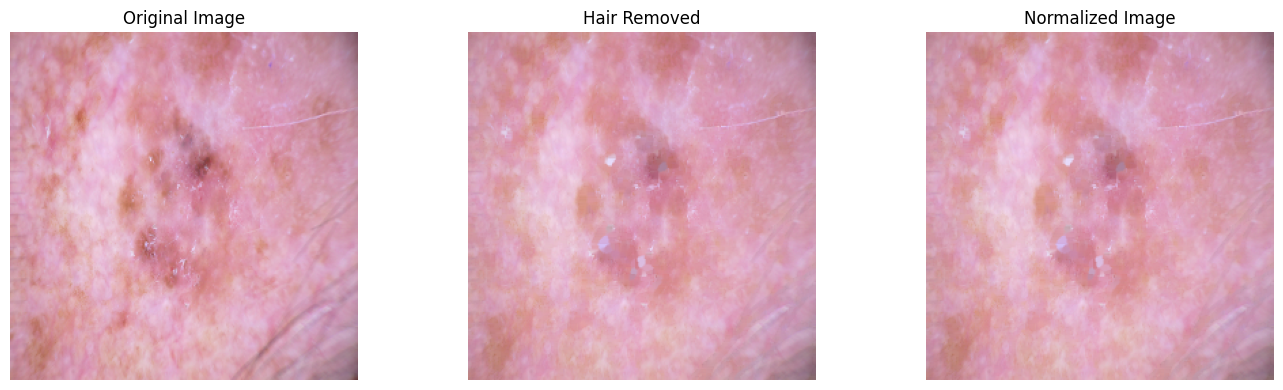

Original shape: (256, 256, 3)
Processed shape: (256, 256, 3)
Normalized range: 0.3529412 0.9843137


In [ ]:
sample_path = train_df["image_path"].iloc[0]

original = cv2.cvtColor(
    cv2.imread(sample_path),
    cv2.COLOR_BGR2RGB
)

original = cv2.resize(original, (WORK_SIZE, WORK_SIZE))
cleaned = remove_hair(original)
normalized = normalize01(cleaned)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].imshow(original)
ax[0].set_title("Original Image")

ax[1].imshow(cleaned)
ax[1].set_title("Hair Removed")

ax[2].imshow(normalized)
ax[2].set_title("Normalized Image")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Original shape:", original.shape)
print("Processed shape:", cleaned.shape)
print("Normalized range:", normalized.min(), normalized.max())

Stage 3 – U-Net Segmentation Output

In [ ]:
print("=" * 50)
print("STAGE 3: U-NET SEGMENTATION")
print("=" * 50)

print("Best Validation Dice:",
      max(history_seg.history["val_dice_coef"]))

print("Best Validation IoU:",
      max(history_seg.history["val_iou_score"]))

print("Final Training Loss:",
      history_seg.history["loss"][-1])

print("Final Validation Loss:",
      history_seg.history["val_loss"][-1])

STAGE 3: U-NET SEGMENTATION
Best Validation Dice: 0.8912861347198486
Best Validation IoU: 0.8291995525360107
Final Training Loss: 0.16599221527576447
Final Validation Loss: 0.24743275344371796


Stage 4 – ROI Extraction Output

In [ ]:
print("=" * 50)
print("STAGE 4: ROI EXTRACTION")
print("=" * 50)

print("Train ROI:", X_train_roi.shape)
print("Validation ROI:", X_val_roi.shape)
print("Test ROI:", X_test_roi.shape)

print("ROI image size:", CLS_SIZE, "x", CLS_SIZE)
print("ROI extraction completed successfully")

STAGE 4: ROI EXTRACTION
Train ROI: (7002, 224, 224, 3)
Validation ROI: (1532, 224, 224, 3)
Test ROI: (1481, 224, 224, 3)
ROI image size: 224 x 224
ROI extraction completed successfully


Stage 5 – Feature Extraction Output

In [ ]:
print("=" * 50)
print("STAGE 5: FEATURE EXTRACTION")
print("=" * 50)

print("Image feature input:", X_train_roi.shape)
print("Clinical feature shape:", X_train_clin.shape)

print("Train labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("Clinical feature dimension:",
      X_train_clin.shape[1])

print("Feature extraction completed")

STAGE 5: FEATURE EXTRACTION
Image feature input: (7002, 224, 224, 3)
Clinical feature shape: (7002, 19)
Train labels: (7002,)
Validation labels: (1532,)
Test labels: (1481,)
Clinical feature dimension: 19
Feature extraction completed


Feature Fusion Output

In [ ]:
print("=" * 50)
print("STAGE 6: FEATURE FUSION")
print("=" * 50)

print("Image feature dimension:", IMG_FEAT)
print("Clinical feature dimension:", CLIN_FEAT)
print("Combined feature dimension:", IMG_FEAT + CLIN_FEAT)
print("Fusion latent dimension:", LATENT)

print("\nFusion Architecture:")
model.summary()

STAGE 6: FEATURE FUSION
Image feature dimension: 256
Clinical feature dimension: 32
Combined feature dimension: 288
Fusion latent dimension: 128

Fusion Architecture:


Model: "EfficientNetB0_Autoencoder_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ roi_image           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical            │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ roi_image[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      1,280 │ clinical[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_gap             │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ img_gap[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 256)       │    327,936 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_features   │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_concat      │ (None, 288)       │          0 │ image_features[0… │
│ (Concatenate)       │                   │            │ clinical_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     36,992 │ feature_concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_latent       │ (None, 128)       │     16,512 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     16,512 │ fusion_latent[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (None, 288)       │     37,152 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ae_loss             │ (None, 128)       │          0 │ feature_concat[0… │
│ (ReconstructionLos… │                   │            │ reconstruction[0… │
│                     │                   │            │ fusion_latent[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ ae_loss[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 11,829,042 (45.12 MB)

 Trainable params: 3,661,411 (13.97 MB)

 Non-trainable params: 844,807 (3.22 MB)

 Optimizer params: 7,322,824 (27.93 MB)

Stage 7 – Classification Output

In [ ]:
print("=" * 50)
print("STAGE 7A: CLASSIFICATION - STAGE 1")
print("=" * 50)

print("Epochs completed:", len(history_1.history["accuracy"]))

print("Best Training Accuracy:",
      max(history_1.history["accuracy"]) * 100, "%")

print("Best Validation Accuracy:",
      max(history_1.history["val_accuracy"]) * 100, "%")

print("Best Validation Loss:",
      min(history_1.history["val_loss"]))

STAGE 7A: CLASSIFICATION - STAGE 1
Epochs completed: 18
Best Training Accuracy: 68.75178813934326 %
Best Validation Accuracy: 69.64752078056335 %
Best Validation Loss: 1.067337989807129


In [ ]:
print("=" * 50)
print("STAGE 7B: CLASSIFICATION - STAGE 2")
print("=" * 50)

print("Epochs completed:", len(history_2.history["accuracy"]))

print("Best Training Accuracy:",
      max(history_2.history["accuracy"]) * 100, "%")

print("Best Validation Accuracy:",
      max(history_2.history["val_accuracy"]) * 100, "%")

print("Best Validation Loss:",
      min(history_2.history["val_loss"]))

STAGE 7B: CLASSIFICATION - STAGE 2
Epochs completed: 12
Best Training Accuracy: 75.60697197914124 %
Best Validation Accuracy: 70.2349841594696 %
Best Validation Loss: 1.1030292510986328


Final Evaluation Output

In [ ]:
print("=" * 50)
print("STAGE 8: FINAL MODEL EVALUATION")
print("=" * 50)

print("Test Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Macro F1 Score:",
      round(f1_score(y_test, y_pred, average="macro") * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    zero_division=0
))

STAGE 8: FINAL MODEL EVALUATION
Test Accuracy: 72.65 %
Balanced Accuracy: 66.2 %
Macro F1 Score: 57.88 %

Classification Report:
              precision    recall  f1-score   support

       akiec       0.34      0.61      0.44        46
         bcc       0.59      0.72      0.65        71
         bkl       0.57      0.63      0.60       168
          df       0.69      0.55      0.61        20
         mel       0.35      0.56      0.43       165
          nv       0.97      0.78      0.86       992
        vasc       0.33      0.79      0.47        19

    accuracy                           0.73      1481
   macro avg       0.55      0.66      0.58      1481
weighted avg       0.80      0.73      0.75      1481



In [ ]:
stage_results = pd.DataFrame([
    ["Stage 1", "Data Collection", len(metadata), "Records"],
    ["Stage 2", "Preprocessing", len(train_df), "Train Images"],
    ["Stage 3", "U-Net Segmentation",
     round(max(history_seg.history["val_dice_coef"]) * 100, 2), "Dice %"],
    ["Stage 4", "ROI Extraction", len(X_train_roi), "Train ROIs"],
    ["Stage 5", "Feature Extraction", X_train_clin.shape[1], "Clinical Features"],
    ["Stage 6", "Feature Fusion", LATENT, "Latent Dimensions"],
    ["Stage 7A", "Classification Stage 1",
     round(max(history_1.history["val_accuracy"]) * 100, 2), "Validation Accuracy %"],
    ["Stage 7B", "Classification Stage 2",
     round(max(history_2.history["val_accuracy"]) * 100, 2), "Validation Accuracy %"],
    ["Stage 8", "Final Test Evaluation",
     round(accuracy_score(y_test, y_pred) * 100, 2), "Test Accuracy %"]
], columns=["Stage", "Process", "Result", "Metric"])

display(stage_results)

,Stage,Process,Result,Metric
0,Stage 1,Data Collection,10015.00,Records
1,Stage 2,Preprocessing,7002.00,Train Images
2,Stage 3,U-Net Segmentation,89.13,Dice %
3,Stage 4,ROI Extraction,7002.00,Train ROIs
4,Stage 5,Feature Extraction,19.00,Clinical Features
5,Stage 6,Feature Fusion,128.00,Latent Dimensions
6,Stage 7A,Classification Stage 1,69.65,Validation Accuracy %
7,Stage 7B,Classification Stage 2,70.23,Validation Accuracy %
8,Stage 8,Final Test Evaluation,72.65,Test Accuracy %


## 12. Reporting checklist
- Report the numbers printed in section 8 (accuracy, balanced accuracy, macro F1, AUC, confusion matrix). Do not quote numbers this run did not produce.
- U-Net was trained on ISBI2016 and applied to HAM10000 (no paired HAM masks), so the ROI is a predicted region.
- Split is grouped by `lesion_id`; clinical inputs are age, sex, localization; `dx_type` was excluded on purpose.
- Accuracy is dominated by the `nv` class (about 67% of HAM10000), so also report balanced accuracy and per-class recall (especially mel, bcc, akiec).
- Academic prototype, not a clinical diagnostic system.